In [1]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay
)

print("PyTorch version:", torch.__version__)

PyTorch version: 2.1.2+cpu


In [3]:
# Step 2 — Generate mobility data

rng = np.random.default_rng(42)
n = 500

df = pd.DataFrame({
    "demand": rng.integers(50, 151, n),
    "supply": rng.integers(45, 141, n),
    "distance_km": rng.uniform(1, 15, n).round(1),
    "peak": rng.choice(
        ["Yes", "No"], n, p=[0.45, 0.55]
    ),
    "weather": rng.choice(
        ["Clear", "Rain"], n, p=[0.75, 0.25]
    )
})

noise = rng.normal(0, 1.7, n)

df["wait_min"] = (
    8
    + 0.12 * (df["demand"] - 100)
    - 0.09 * (df["supply"] - 90)
    + 0.25 * (df["distance_km"] - 7)
    + 1.5 * (df["peak"] == "Yes")
    + 2.0 * (df["weather"] == "Rain")
    + noise
).clip(lower=0.5).round(2)

# Binary target: late if wait >= 10 minutes
df["late"] = (df["wait_min"] >= 10).astype(int)

display(df.head())
print("Shape:", df.shape)
print(df["late"].value_counts())

,demand,supply,distance_km,peak,weather,wait_min,late
0,59,55,11.3,Yes,Clear,7.06,0
1,128,107,13.4,No,Rain,14.97,1
2,116,137,13.9,Yes,Clear,6.87,0
3,94,128,8.1,Yes,Clear,5.15,0
4,93,71,8.3,No,Rain,10.20,1


Shape: (500, 7)
late
0    290
1    210
Name: count, dtype: int64


In [4]:
# function 1: convert data to Tensor
def to_tensors(X, y):
    X_tensor = torch.tensor(
        np.asarray(X),
        dtype=torch.float32
    )

    y_tensor = torch.tensor(
        np.asarray(y).reshape(-1, 1),
        dtype=torch.float32
    )

    return X_tensor, y_tensor

# function 2: model training
def train_torch_model(
    model,
    X_train_tensor,
    y_train_tensor,
    loss_fn,
    epochs=1200,
    lr=0.05
):
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    loss_history = []

    for epoch in range(epochs):

        model.train()

        # 1. Clear previous gradients
        optimizer.zero_grad()

        # 2. Forward pass
        outputs = model(X_train_tensor)

        # 3. Calculate loss
        loss = loss_fn(outputs, y_train_tensor)

        # 4. Backpropagation
        loss.backward()

        # 5. Update parameters
        optimizer.step()

        loss_history.append(loss.item())

    model.eval()

    return loss_history

late
0    290
1    210
Name: count, dtype: int64
late
0    0.58
1    0.42
Name: proportion, dtype: float64


<Axes: xlabel='late'>

Text(0.5, 0, 'Late (0 = No, 1 = Yes)')

Text(0, 0.5, 'Number of trips')

Text(0.5, 1.0, 'Late Trip Distribution')

(array([0, 1]), [Text(0, 0, '0'), Text(1, 0, '1')])

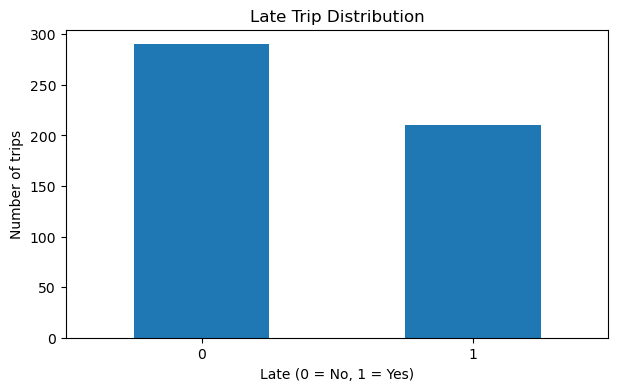

In [5]:
# Task 1 — Examine the binary target

print(df["late"].value_counts())

print(
    df["late"].value_counts(normalize=True)
)

df["late"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(7, 4)
)

plt.xlabel("Late (0 = No, 1 = Yes)")
plt.ylabel("Number of trips")
plt.title("Late Trip Distribution")
plt.xticks(rotation=0)

plt.show()

In [6]:
# Task 2 — Preprocess data and train Logistic Regression
# Step A — Split data

features = [
    "demand",
    "supply",
    "distance_km",
    "peak",
    "weather"
]

X_log = df[features]
y_log = df["late"]

X_train_l, X_test_l, y_train_l, y_test_l = (
    train_test_split(
        X_log,
        y_log,
        test_size=0.25,
        random_state=42,
        stratify=y_log
    )
)

In [7]:
# Step B — Preprocess and convert to Tensor

preprocess_log = ColumnTransformer([
    (
        "num",
        StandardScaler(),
        ["demand", "supply", "distance_km"]
    ),
    (
        "cat",
        OneHotEncoder(
            drop="first",
            handle_unknown="ignore",
            sparse_output=False
        ),
        ["peak", "weather"]
    )
])

X_train_processed_l = preprocess_log.fit_transform(
    X_train_l
)

X_test_processed_l = preprocess_log.transform(
    X_test_l
)

X_train_log_t, y_train_log_t = to_tensors(
    X_train_processed_l, y_train_l
)

X_test_log_t, y_test_log_t = to_tensors(
    X_test_processed_l, y_test_l
)

print("Training shape:", X_train_log_t.shape)

Training shape: torch.Size([375, 5])


In [8]:
# Step C — Define Logistic Regression

torch.manual_seed(42)

logistic_model = nn.Linear(
    in_features=5,
    out_features=1
)

loss_fn_log = nn.BCEWithLogitsLoss()

In [9]:
# Step D — Train

log_history = train_torch_model(
    model=logistic_model,
    X_train_tensor=X_train_log_t,
    y_train_tensor=y_train_log_t,
    loss_fn=loss_fn_log,
    epochs=1500,
    lr=0.03
)

print("Final BCE Loss:", log_history[-1])

Final BCE Loss: 0.21746118366718292


<Figure size 800x400 with 0 Axes>

Text(0.5, 0, 'Epoch')

Text(0, 0.5, 'Binary Cross Entropy Loss')

Text(0.5, 1.0, 'Logistic Regression — Training Loss')

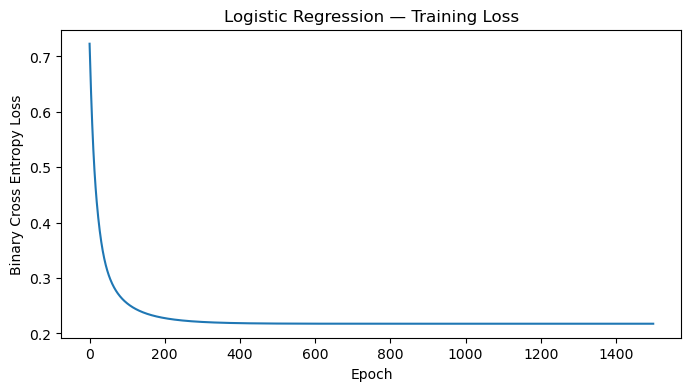

In [10]:
# Visualize training:

plt.figure(figsize=(8, 4))

plt.plot(log_history)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross Entropy Loss")
plt.title("Logistic Regression — Training Loss")

plt.show()

In [11]:
# Task 3 — Predict probabilities and classes

logistic_model.eval()

with torch.no_grad():

    # Linear outputs: logits
    logits = logistic_model(X_test_log_t)

    # Convert logits to probabilities
    probabilities = torch.sigmoid(logits)

    # Convert probabilities to binary predictions
    predictions = (
        probabilities >= 0.5
    ).int()

y_prob = probabilities.numpy().flatten()
y_pred_log = predictions.numpy().flatten()

results = pd.DataFrame({
    "Actual": y_test_l.to_numpy(),
    "Predicted Probability": y_prob,
    "Predicted Class": y_pred_log
})

display(results.head(10))

# Question: If a model outputs 0.48 as the probability of a late trip, what is the predicted class when the threshold is 0.5?

# Answer: 0 (Not Late).

Linear(in_features=5, out_features=1, bias=True)

,Actual,Predicted Probability,Predicted Class
0,0,0.000619,0
1,1,0.996983,1
2,0,0.128444,0
3,0,0.637001,1
4,0,0.160082,0
5,0,0.139237,0
6,0,0.009098,0
7,1,0.955267,1
8,1,0.999733,1
9,1,0.998425,1


[[66  7]
 [10 42]]


Text(0.5, 1.0, 'PyTorch Logistic Regression')

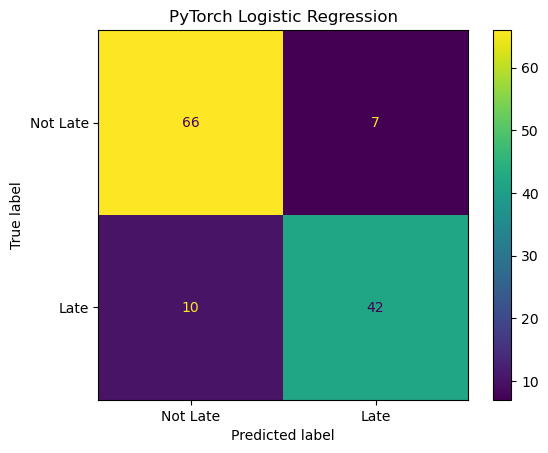

In [12]:
# Task 4 — Confusion Matrix

cm = confusion_matrix(
    y_test_l,
    y_pred_log
)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Late", "Late"]
).plot()

plt.title("PyTorch Logistic Regression")
plt.show()

In [13]:
# Task 5 — Classification Metrics

accuracy = accuracy_score(
    y_test_l, y_pred_log
)

precision = precision_score(
    y_test_l, y_pred_log
)

recall = recall_score(
    y_test_l, y_pred_log
)

print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")

Accuracy:  0.864
Precision: 0.857
Recall:    0.808


In [14]:
# Task 6 — Compare Classification Thresholds

thresholds = [0.3, 0.5, 0.7]

comparison = []

for threshold in thresholds:

    pred = (y_prob >= threshold).astype(int)

    comparison.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test_l, pred
        ),
        "Recall": recall_score(
            y_test_l, pred
        )
    })

threshold_df = pd.DataFrame(comparison)

display(threshold_df.round(3))

# Short-answer question
# Suppose the company wants to identify as many potentially late trips as possible so that drivers can be reassigned proactively. 
# Which threshold would you recommend among the three tested values?

,Threshold,Precision,Recall
0,0.3,0.810,0.904
1,0.5,0.857,0.808
2,0.7,0.929,0.750


ROC AUC: 0.950


Text(0.5, 1.0, 'PyTorch Logistic Regression — ROC Curve')

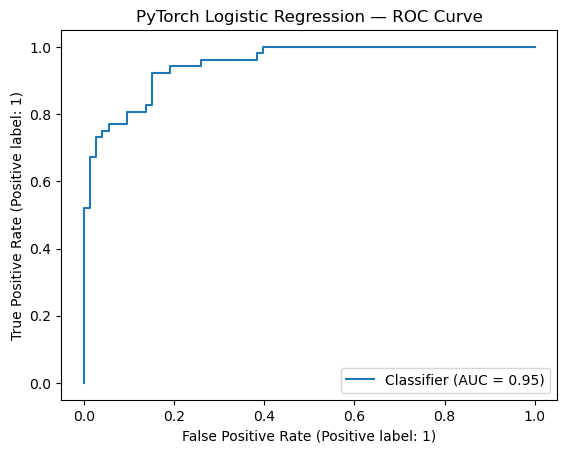

In [15]:
# Task 7 — ROC Curve and AUC

auc = roc_auc_score(
    y_test_l,
    y_prob
)

print(f"ROC AUC: {auc:.3f}")

RocCurveDisplay.from_predictions(
    y_test_l,
    y_prob
)

plt.title("PyTorch Logistic Regression — ROC Curve")
plt.show()

In [16]:
# Task 8 — Interpret the model coefficients
# Logistic Regression coefficients describe changes in log-odds, not direct changes in probability.

feature_names = preprocess_log.get_feature_names_out()

coefficients = (
    logistic_model.weight.detach()
    .numpy()
    .flatten()
)

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

display(coef_df)


# Analysis questions
# 1. Which predictors have positive coefficients?
# 2. Which predictors have negative coefficients?
# 3. Why shouldn't a coefficient of 0.5 be interpreted as a 50% increase in probability?

,Feature,Coefficient
0,num__demand,3.975147
1,num__supply,-2.772044
2,num__distance_km,1.259284
3,cat__peak_Yes,1.282712
4,cat__weather_Rain,2.739201


In [17]:
# Task 9 — Predict a New Ride Request

new_trip = pd.DataFrame({
    "demand": [125],
    "supply": [65],
    "distance_km": [8.0],
    "peak": ["Yes"],
    "weather": ["Rain"]
})

new_trip_processed = preprocess_log.transform(
    new_trip
)

new_trip_tensor = torch.tensor(
    new_trip_processed,
    dtype=torch.float32
)

logistic_model.eval()

with torch.no_grad():

    logit = logistic_model(new_trip_tensor)

    probability = torch.sigmoid(logit).item()

print(f"P(Late): {probability:.4f}")

print(
    "Prediction:",
    "Late" if probability >= 0.5 else "Not Late"
)

Linear(in_features=5, out_features=1, bias=True)

P(Late): 0.9996
Prediction: Late
